# Exploratory Data Analysis (EDA) for Scraped News Data
### LimeoX AI/ML Foundation Training — Practical Lecture Notebook

**Goal:** Understand distributions, patterns, relationships, source behavior, content quality, and time-based trends before feature engineering or machine learning.

Designed for news data with fields such as `news_url_clean`, `title_clean`, `content_clean`, `published_at_utc`, `scraped_at_utc`, `author_clean`, `domain`, and optional `article_niche`/`category`.

**EDA principle:** describe and investigate the data; do not silently modify or delete records. Cleaning and validation belong in earlier pipeline stages.

## Learning outcomes

Students will learn to:
1. Profile dataset shape, schema, data types, missingness, uniqueness, and duplicates.
2. Analyze title/content lengths and source/category distributions.
3. Explore publication-time patterns and scrape delay.
4. Compare groups and inspect relationships between variables.
5. Identify suspicious extraction patterns without automatically deleting records.
6. Visualize findings and write evidence-based recommendations.

**Workflow:** Load → Profile → Univariate analysis → Grouped analysis → Time analysis → Relationships → Anomaly investigation → Findings.

## 1. Setup
Install dependencies if needed: `pip install pandas numpy matplotlib`.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_SEED = 42
OUTPUT_DIR = Path("eda_output")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Pandas:", pd.__version__, "| NumPy:", np.__version__)

Pandas: 3.0.5 | NumPy: 1.26.4


## 2. Load data

The loader checks likely outputs from the previous preprocessing/validation notebooks. If no CSV is found, it generates synthetic demonstration data so the notebook can run end-to-end. Synthetic data is for practice only, not real business conclusions.

In [2]:
CANDIDATE_PATHS = [
    Path("validation_output/validated_all_records.csv"),
    Path("preprocessed_output/news_clean.csv"),
    Path("news_clean.csv"),
    Path("data/news.csv"),
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)

if DATA_PATH is not None:
    df = pd.read_csv(DATA_PATH, low_memory=False)
    print("Loaded:", DATA_PATH.resolve())
else:
    print("No candidate CSV found — using synthetic demonstration data.")
    rng = np.random.default_rng(RANDOM_SEED)
    domains = ["example-finance.com", "daily-market.test", "global-news.test", "tech-wire.test"]
    authors = ["A. Khan", "S. Ahmed", "Staff Writer", None, "Editorial Desk"]
    niches = ["Markets", "Technology", "Business", "World"]
    n = 240
    published = pd.to_datetime("2026-08-01", utc=True) + pd.to_timedelta(rng.integers(0, 60*24*60, size=n), unit="m")
    title_templates = [
        "Company reports quarterly earnings amid market uncertainty",
        "Technology shares rise as investors assess new forecasts",
        "Oil prices move after latest economic data release",
        "Analysts discuss outlook for global financial markets",
        "New policy announcement affects business confidence",
        "Major technology firm introduces a new product",
        "Stocks fall as traders react to central bank comments",
        "Retail sales data signals a shift in consumer demand",
    ]
    titles = [title_templates[i % len(title_templates)] for i in rng.permutation(n)]
    contents = []
    for i in range(n):
        length = int(max(80, rng.lognormal(mean=6.0, sigma=0.65)))
        contents.append(("Synthetic article text for EDA practice. " * (length // 40 + 2))[:length])
    df = pd.DataFrame({
        "news_url_clean": [f"https://{domains[i % len(domains)]}/article/{i}" for i in range(n)],
        "title_clean": titles,
        "content_clean": contents,
        "published_at_utc": published.astype(str),
        "scraped_at_utc": (published + pd.to_timedelta(rng.integers(5, 180, size=n), unit="m")).astype(str),
        "author_clean": [authors[i % len(authors)] for i in range(n)],
        "domain": [domains[i % len(domains)] for i in range(n)],
        "article_niche": [niches[i % len(niches)] for i in range(n)],
    })

print("Dataset shape:", df.shape)
display(df.head())

No candidate CSV found — using synthetic demonstration data.
Dataset shape: (240, 8)


,news_url_clean,title_clean,content_clean,published_at_utc,scraped_at_utc,author_clean,domain,article_niche
0,https://example-finance.com/article/0,Retail sales data signals a shift in consumer demand,Synthetic article text for EDA practice. Synthetic article text for EDA practice. Synthetic article text for EDA pra...,2026-08-06 08:31:00+00:00,2026-08-06 10:40:00+00:00,A. Khan,example-finance.com,Markets
1,https://daily-market.test/article/1,Technology shares rise as investors assess new forecasts,Synthetic article text for EDA practice. Synthetic article text for EDA practice. Synthetic article text for EDA pra...,2026-09-16 10:29:00+00:00,2026-09-16 11:03:00+00:00,S. Ahmed,daily-market.test,Technology
2,https://global-news.test/article/2,New policy announcement affects business confidence,Synthetic article text for EDA practice. Synthetic article text for EDA practice. Synthetic article text for EDA pra...,2026-09-09 06:34:00+00:00,2026-09-09 07:52:00+00:00,Staff Writer,global-news.test,Business
3,https://tech-wire.test/article/3,New policy announcement affects business confidence,Synthetic article text for EDA practice. Synthetic article text for EDA practice. Synthetic article text for EDA pra...,2026-08-27 07:59:00+00:00,2026-08-27 10:30:00+00:00,NaN,tech-wire.test,World
4,https://example-finance.com/article/4,Oil prices move after latest economic data release,Synthetic article text for EDA practice. Synthetic article text for EDA practice. Synthetic article text for EDA pra...,2026-08-26 23:32:00+00:00,2026-08-27 02:18:00+00:00,Editorial Desk,example-finance.com,Markets


## 3. Map common field names

The mapping allows the notebook to work with several common column naming conventions without overwriting the source columns.

In [3]:
def first_existing(columns, candidates):
    return next((name for name in candidates if name in columns), None)

COLS = {
    "url": first_existing(df.columns, ["news_url_clean", "url", "news_url", "shared_url"]),
    "title": first_existing(df.columns, ["title_clean", "title", "headline"]),
    "content": first_existing(df.columns, ["content_clean", "content", "article_text", "text", "body"]),
    "published": first_existing(df.columns, ["published_at_utc", "published_at", "published_date", "publication_time"]),
    "scraped": first_existing(df.columns, ["scraped_at_utc", "scraped_at", "scrape_time", "scraped_datetime"]),
    "author": first_existing(df.columns, ["author_clean", "author", "byline"]),
    "domain": first_existing(df.columns, ["domain", "source_domain", "website"]),
    "category": first_existing(df.columns, ["article_niche", "category", "topic", "section"]),
}
print(COLS)

{'url': 'news_url_clean', 'title': 'title_clean', 'content': 'content_clean', 'published': 'published_at_utc', 'scraped': 'scraped_at_utc', 'author': 'author_clean', 'domain': 'domain', 'category': 'article_niche'}


## 4. Dataset overview and schema
Check shape, data types, missingness, uniqueness, exact duplicate rows, and memory use.

In [4]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_non_null": df.nunique(dropna=True),
})
display(overview.sort_values("missing_pct", ascending=False))
print(f"Rows: {len(df):,} | Columns: {df.shape[1]:,}")
print("Duplicate column names:", df.columns[df.columns.duplicated()].tolist())
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Memory usage (MB):", round(df.memory_usage(deep=True).sum() / 1024**2, 2))

,dtype,non_null,missing,missing_pct,unique_non_null
author_clean,str,192,48,20.0,4
news_url_clean,str,240,0,0.0,240
title_clean,str,240,0,0.0,8
content_clean,str,240,0,0.0,208
published_at_utc,str,240,0,0.0,240
scraped_at_utc,str,240,0,0.0,240
domain,str,240,0,0.0,4
article_niche,str,240,0,0.0,4


Rows: 240 | Columns: 8
Duplicate column names: []
Exact duplicate rows: 0
Memory usage (MB): 0.17


## 5. Missingness and completeness
Missing values may be informative: author or publication time may be absent more often for particular sources. Missing does not automatically mean invalid.

,missing,missing_pct
author_clean,48,20.0
news_url_clean,0,0.0
title_clean,0,0.0
content_clean,0,0.0
published_at_utc,0,0.0
scraped_at_utc,0,0.0
domain,0,0.0
article_niche,0,0.0


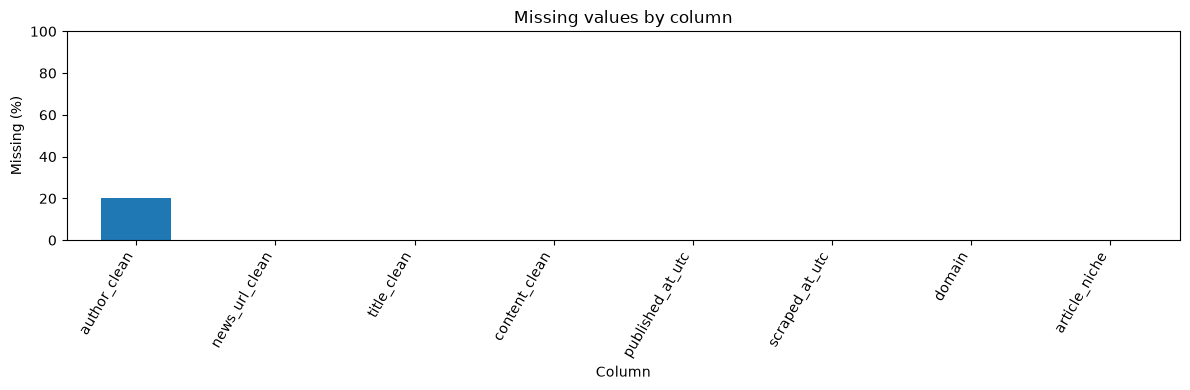

In [5]:
missing_summary = overview[["missing", "missing_pct"]].sort_values("missing_pct", ascending=False)
display(missing_summary)
ax = missing_summary["missing_pct"].plot(kind="bar", figsize=(12, 4))
ax.set_title("Missing values by column")
ax.set_ylabel("Missing (%)")
ax.set_xlabel("Column")
ax.set_ylim(0, 100)
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [6]:
if COLS["domain"]:
    tmp = df.copy()
    tmp["_domain_for_group"] = tmp[COLS["domain"]].fillna("(missing domain)")
    records = []
    for domain, group in tmp.groupby("_domain_for_group", dropna=False):
        row = {"domain": domain, "articles": len(group)}
        if COLS["author"]:
            row["author_missing_pct"] = group[COLS["author"]].isna().mean() * 100
        if COLS["published"]:
            row["published_missing_pct"] = group[COLS["published"]].isna().mean() * 100
        records.append(row)
    display(pd.DataFrame(records).sort_values("articles", ascending=False).round(2))
else:
    print("No domain/source field detected.")

,domain,articles,author_missing_pct,published_missing_pct
0,daily-market.test,60,20.0,0.0
1,example-finance.com,60,20.0,0.0
2,global-news.test,60,20.0,0.0
3,tech-wire.test,60,20.0,0.0


## 6. Uniqueness and duplicate patterns

For news data, exact row duplicates, duplicate URLs, repeated titles, and repeated bodies are different signals. Treat them as **candidates to investigate**, not automatic deletion instructions.

In [7]:
duplicate_stats = {
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "duplicate_url_rows": int(df[COLS["url"]].duplicated(keep=False).sum()) if COLS["url"] else None,
    "duplicate_title_rows": int(df[COLS["title"]].astype("string").str.strip().duplicated(keep=False).sum()) if COLS["title"] else None,
    "duplicate_content_rows": int(df[COLS["content"]].astype("string").str.strip().duplicated(keep=False).sum()) if COLS["content"] else None,
}
display(pd.Series(duplicate_stats, name="row_count").to_frame())

,row_count
exact_duplicate_rows,0
duplicate_url_rows,0
duplicate_title_rows,240
duplicate_content_rows,78


In [8]:
if COLS["url"]:
    display(df[df[COLS["url"]].duplicated(keep=False)].sort_values(COLS["url"]).head(20))
if COLS["title"]:
    title_dupes = df[df[COLS["title"]].astype("string").str.strip().duplicated(keep=False)]
    cols = [c for c in [COLS["domain"], COLS["published"], COLS["title"], COLS["url"]] if c]
    display(title_dupes[cols].sort_values(COLS["title"]).head(20))

,news_url_clean,title_clean,content_clean,published_at_utc,scraped_at_utc,author_clean,domain,article_niche


,domain,published_at_utc,title_clean,news_url_clean
13,daily-market.test,2026-09-15 16:02:00+00:00,Analysts discuss outlook for global financial markets,https://daily-market.test/article/13
17,daily-market.test,2026-08-08 16:29:00+00:00,Analysts discuss outlook for global financial markets,https://daily-market.test/article/17
19,tech-wire.test,2026-08-28 00:33:00+00:00,Analysts discuss outlook for global financial markets,https://tech-wire.test/article/19
27,tech-wire.test,2026-09-19 08:46:00+00:00,Analysts discuss outlook for global financial markets,https://tech-wire.test/article/27
30,global-news.test,2026-08-28 00:39:00+00:00,Analysts discuss outlook for global financial markets,https://global-news.test/article/30
37,daily-market.test,2026-09-19 15:47:00+00:00,Analysts discuss outlook for global financial markets,https://daily-market.test/article/37
38,global-news.test,2026-08-17 14:32:00+00:00,Analysts discuss outlook for global financial markets,https://global-news.test/article/38
45,daily-market.test,2026-09-28 05:48:00+00:00,Analysts discuss outlook for global financial markets,https://daily-market.test/article/45
49,daily-market.test,2026-09-16 16:52:00+00:00,Analysts discuss outlook for global financial markets,https://daily-market.test/article/49
56,example-finance.com,2026-09-02 19:03:00+00:00,Analysts discuss outlook for global financial markets,https://example-finance.com/article/56


## 7. Text-length distributions

Article length is both a content characteristic and an extraction diagnostic. Very short text may indicate failed extraction or a genuinely brief item; very long text may contain navigation, comments, or concatenated pages.

In [9]:
if COLS["title"]:
    df["_title_chars"] = df[COLS["title"]].astype("string").str.len()
    df["_title_words"] = df[COLS["title"]].astype("string").str.split().str.len()
if COLS["content"]:
    df["_content_chars"] = df[COLS["content"]].astype("string").str.len()
    df["_content_words"] = df[COLS["content"]].astype("string").str.split().str.len()

length_cols = [c for c in ["_title_chars", "_title_words", "_content_chars", "_content_words"] if c in df.columns]
display(df[length_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
_title_chars,240.0,52.375,3.432706,46.0,46.0,46.0,50.75,52.5,53.75,58.0,58.0,58.0
_title_words,240.0,7.625,0.99423,6.0,6.0,6.0,7.0,7.5,8.25,9.0,9.0,9.0
_content_chars,240.0,496.591667,333.549906,80.0,88.39,127.7,269.75,428.0,625.5,1144.45,1723.75,2183.0
_content_words,240.0,72.95,48.79165,12.0,13.0,18.95,39.5,62.0,91.5,168.05,252.4,319.0


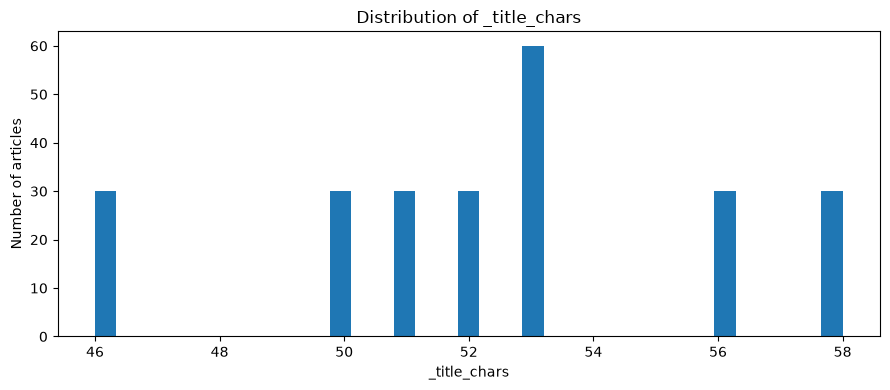

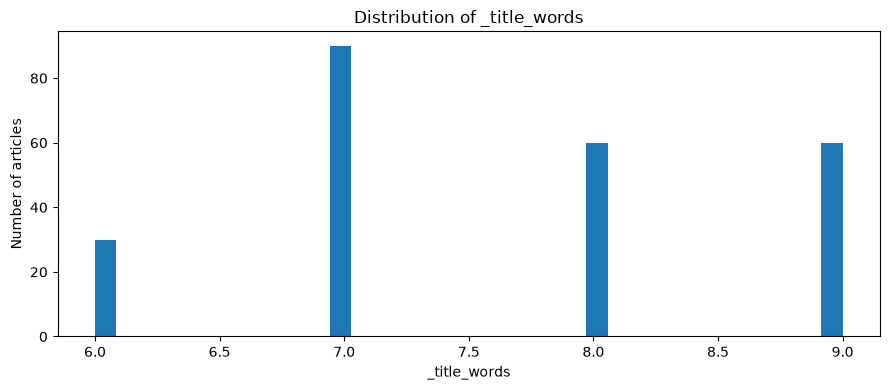

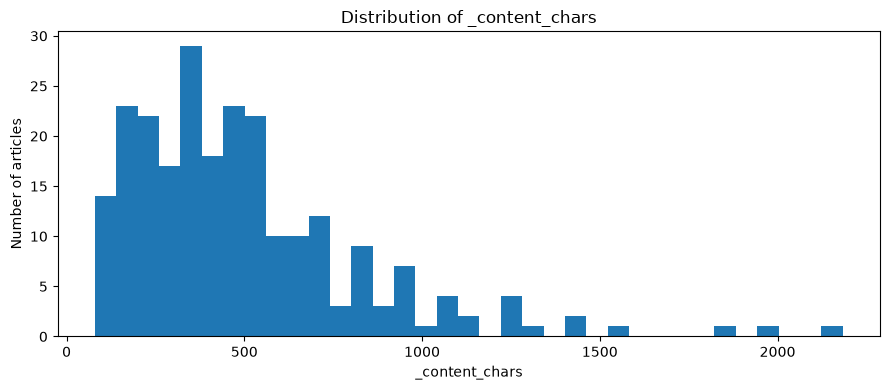

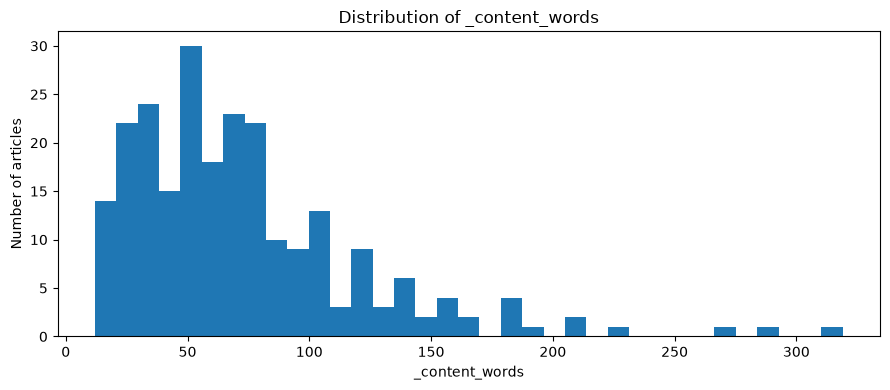

In [10]:
for col in length_cols:
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    if len(values):
        plt.figure(figsize=(9, 4))
        plt.hist(values, bins=35)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Number of articles")
        plt.tight_layout()
        plt.show()

In [11]:
if "_content_words" in df.columns:
    display(df.nsmallest(10, "_content_words")[[c for c in [COLS["domain"], COLS["title"], COLS["published"], "_content_words", COLS["url"]] if c]])
    display(df.nlargest(10, "_content_words")[[c for c in [COLS["domain"], COLS["title"], COLS["published"], "_content_words", COLS["url"]] if c]])

,domain,title_clean,published_at_utc,_content_words,news_url_clean
16,example-finance.com,Stocks fall as traders react to central bank comments,2026-08-31 19:02:00+00:00,12,https://example-finance.com/article/16
227,tech-wire.test,Retail sales data signals a shift in consumer demand,2026-09-04 18:04:00+00:00,12,https://tech-wire.test/article/227
63,tech-wire.test,Analysts discuss outlook for global financial markets,2026-09-28 01:12:00+00:00,13,https://tech-wire.test/article/63
113,daily-market.test,Technology shares rise as investors assess new forecasts,2026-08-28 12:50:00+00:00,13,https://daily-market.test/article/113
134,global-news.test,Major technology firm introduces a new product,2026-09-17 16:40:00+00:00,13,https://global-news.test/article/134
68,example-finance.com,Company reports quarterly earnings amid market uncertainty,2026-08-05 13:56:00+00:00,15,https://example-finance.com/article/68
186,global-news.test,Major technology firm introduces a new product,2026-08-10 23:20:00+00:00,15,https://global-news.test/article/186
100,example-finance.com,Analysts discuss outlook for global financial markets,2026-09-19 23:08:00+00:00,16,https://example-finance.com/article/100
131,tech-wire.test,New policy announcement affects business confidence,2026-09-03 05:09:00+00:00,17,https://tech-wire.test/article/131
221,daily-market.test,New policy announcement affects business confidence,2026-08-28 08:19:00+00:00,17,https://daily-market.test/article/221


,domain,title_clean,published_at_utc,_content_words,news_url_clean
202,global-news.test,Retail sales data signals a shift in consumer demand,2026-08-30 16:53:00+00:00,319,https://global-news.test/article/202
229,daily-market.test,Major technology firm introduces a new product,2026-08-11 14:33:00+00:00,284,https://daily-market.test/article/229
98,global-news.test,Technology shares rise as investors assess new forecasts,2026-09-08 04:56:00+00:00,268,https://global-news.test/article/98
176,example-finance.com,Stocks fall as traders react to central bank comments,2026-09-13 00:33:00+00:00,228,https://example-finance.com/article/176
175,tech-wire.test,Major technology firm introduces a new product,2026-08-28 17:06:00+00:00,210,https://tech-wire.test/article/175
190,global-news.test,Analysts discuss outlook for global financial markets,2026-09-11 00:31:00+00:00,208,https://global-news.test/article/190
47,tech-wire.test,Company reports quarterly earnings amid market uncertainty,2026-09-23 14:05:00+00:00,193,https://tech-wire.test/article/47
35,tech-wire.test,Retail sales data signals a shift in consumer demand,2026-08-04 19:53:00+00:00,183,https://tech-wire.test/article/35
32,example-finance.com,New policy announcement affects business confidence,2026-08-06 12:40:00+00:00,182,https://example-finance.com/article/32
23,tech-wire.test,New policy announcement affects business confidence,2026-09-25 14:32:00+00:00,181,https://tech-wire.test/article/23


## 8. Source/domain distribution
Inspect which domains contribute most, whether the data is concentrated in a few sites, and how article lengths vary by source.

,articles
domain,
example-finance.com,60
daily-market.test,60
global-news.test,60
tech-wire.test,60


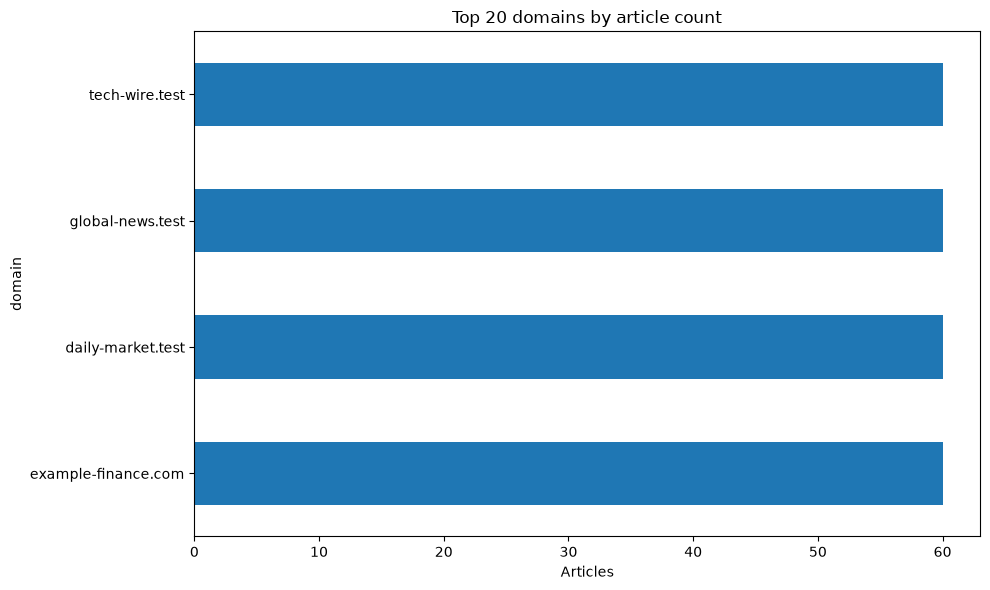

,share_pct
domain,
example-finance.com,25.0
daily-market.test,25.0
global-news.test,25.0
tech-wire.test,25.0


In [12]:
if COLS["domain"]:
    source_counts = df[COLS["domain"]].fillna("(missing domain)").value_counts()
    display(source_counts.rename("articles").to_frame().head(30))
    ax = source_counts.head(20).sort_values().plot(kind="barh", figsize=(10, 6))
    ax.set_title("Top 20 domains by article count")
    ax.set_xlabel("Articles")
    plt.tight_layout()
    plt.show()
    display((source_counts / source_counts.sum() * 100).rename("share_pct").to_frame().head(20).round(2))
else:
    print("No domain/source field detected.")

In [13]:
if COLS["domain"] and "_content_words" in df.columns:
    source_length = df.groupby(COLS["domain"], dropna=False).agg(
        articles=("_content_words", "size"),
        median_content_words=("_content_words", "median"),
        mean_content_words=("_content_words", "mean"),
        p95_content_words=("_content_words", lambda s: s.quantile(.95)),
    )
    display(source_length.query("articles >= 3").sort_values("articles", ascending=False).round(1).head(30))

,articles,median_content_words,mean_content_words,p95_content_words
domain,,,,
daily-market.test,60,62.0,75.0,129.5
example-finance.com,60,54.5,66.6,154.0
global-news.test,60,67.5,78.0,182.3
tech-wire.test,60,56.5,72.2,181.1


## 9. Category/niche distribution
Class imbalance matters for classification, recommendation, and topic reporting. Inspect category labels before building models.

,articles
article_niche,
Markets,60
Technology,60
Business,60
World,60


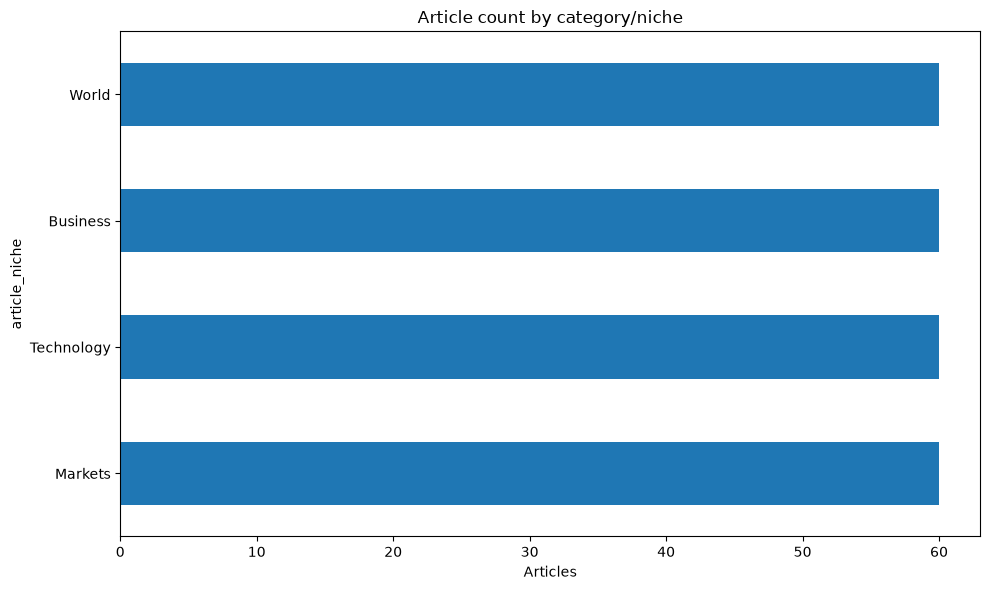

In [14]:
if COLS["category"]:
    category_counts = df[COLS["category"]].fillna("(missing category)").value_counts()
    display(category_counts.rename("articles").to_frame())
    ax = category_counts.head(25).sort_values().plot(kind="barh", figsize=(10, 6))
    ax.set_title("Article count by category/niche")
    ax.set_xlabel("Articles")
    plt.tight_layout()
    plt.show()
else:
    print("No category/niche field detected.")

## 10. Publication-time patterns

Convert timestamps to UTC explicitly. Invalid or missing timestamps become `NaT` and are counted. Explore coverage, articles per day/hour, weekday patterns, and publication-to-scrape delay.

**Caution:** scraper schedules, source timezone conventions, and incomplete history can create apparent trends.

Valid publication timestamps: 240 / 240
Earliest: 2026-08-01 10:36:00+00:00 | Latest: 2026-09-29 18:23:00+00:00
Coverage days: 59.32


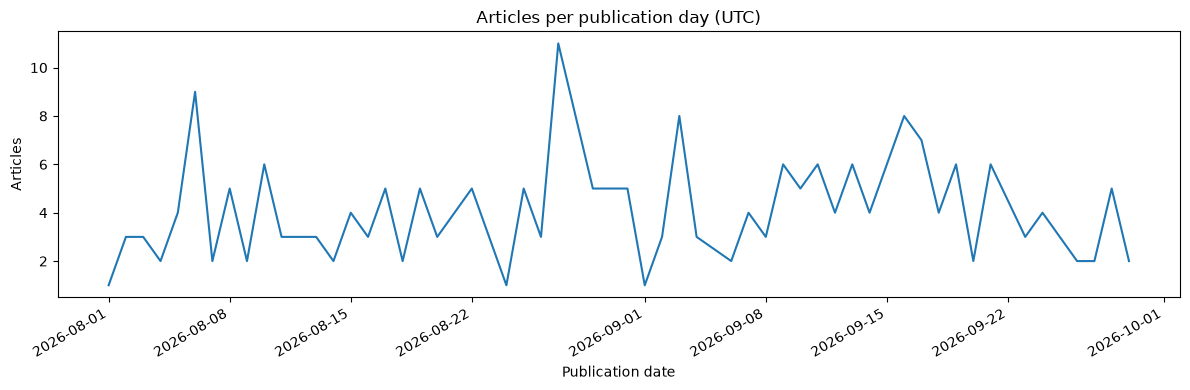

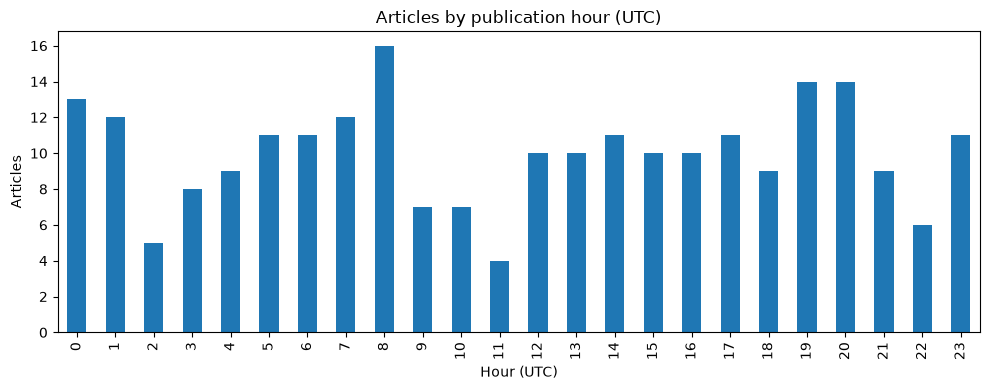

,articles
_published_day_name,
Monday,39
Tuesday,24
Wednesday,35
Thursday,50
Friday,32
Saturday,32
Sunday,28


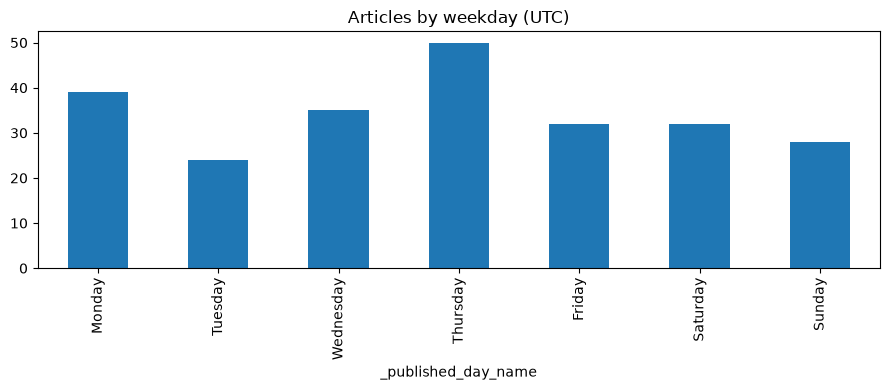

In [15]:
if COLS["published"]:
    df["_published_dt"] = pd.to_datetime(df[COLS["published"]], errors="coerce", utc=True)
    valid_pub = df["_published_dt"].dropna()
    print("Valid publication timestamps:", len(valid_pub), "/", len(df))
    if len(valid_pub):
        print("Earliest:", valid_pub.min(), "| Latest:", valid_pub.max())
        print("Coverage days:", round((valid_pub.max() - valid_pub.min()).total_seconds() / 86400, 2))
        df["_published_date"] = df["_published_dt"].dt.floor("D")
        df["_published_hour_utc"] = df["_published_dt"].dt.hour
        df["_published_day_name"] = df["_published_dt"].dt.day_name()
        daily = df.groupby("_published_date").size()
        ax = daily.plot(figsize=(12, 4))
        ax.set_title("Articles per publication day (UTC)")
        ax.set_xlabel("Publication date")
        ax.set_ylabel("Articles")
        plt.tight_layout()
        plt.show()
        hourly = df["_published_hour_utc"].value_counts().sort_index().reindex(range(24), fill_value=0)
        ax = hourly.plot(kind="bar", figsize=(10, 4))
        ax.set_title("Articles by publication hour (UTC)")
        ax.set_xlabel("Hour (UTC)")
        ax.set_ylabel("Articles")
        plt.tight_layout()
        plt.show()
        order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
        weekdays = df["_published_day_name"].value_counts().reindex(order, fill_value=0)
        display(weekdays.rename("articles").to_frame())
        weekdays.plot(kind="bar", figsize=(9, 4), title="Articles by weekday (UTC)")
        plt.tight_layout()
        plt.show()
else:
    print("No publication timestamp field detected.")

,_publish_to_scrape_minutes
count,240.000000
mean,97.841667
std,50.844252
min,5.000000
1%,6.000000
5%,12.000000
50%,98.000000
95%,173.000000
99%,178.000000
max,179.000000


Negative publication-to-scrape delays: 0


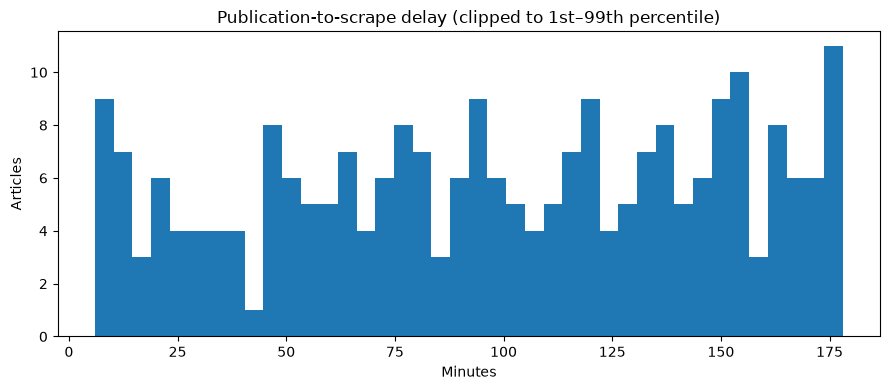

In [16]:
if COLS["published"] and COLS["scraped"]:
    df["_scraped_dt"] = pd.to_datetime(df[COLS["scraped"]], errors="coerce", utc=True)
    df["_publish_to_scrape_minutes"] = (df["_scraped_dt"] - df["_published_dt"]).dt.total_seconds() / 60
    display(df["_publish_to_scrape_minutes"].describe(percentiles=[.01, .05, .5, .95, .99]).to_frame())
    print("Negative publication-to-scrape delays:", int((df["_publish_to_scrape_minutes"] < 0).sum()))
    delay = df["_publish_to_scrape_minutes"].dropna()
    if len(delay):
        clipped = delay.clip(lower=delay.quantile(.01), upper=delay.quantile(.99))
        plt.figure(figsize=(9, 4))
        plt.hist(clipped, bins=40)
        plt.title("Publication-to-scrape delay (clipped to 1st–99th percentile)")
        plt.xlabel("Minutes")
        plt.ylabel("Articles")
        plt.tight_layout()
        plt.show()
else:
    print("Both publication and scrape timestamps are required for scrape-delay analysis.")

## 11. Relationships between variables
Compare title length with article length and inspect category mix by domain. Correlation is descriptive, not causal.

Pearson correlation: -0.036
Spearman correlation: -0.044


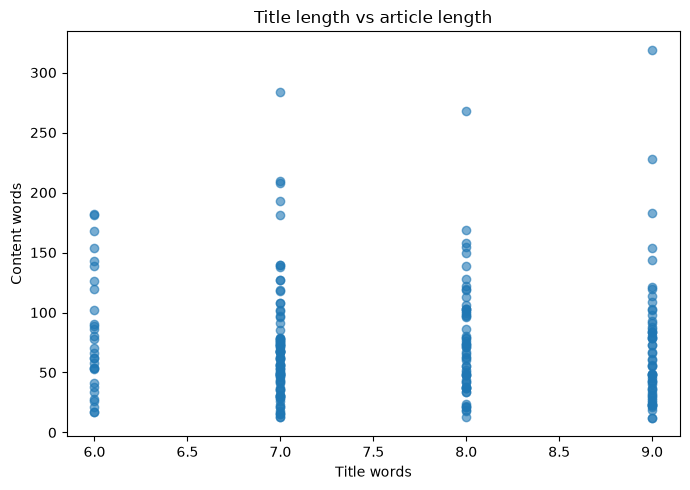

In [17]:
if "_title_words" in df.columns and "_content_words" in df.columns:
    pair = df[["_title_words", "_content_words"]].dropna()
    if len(pair) >= 2:
        print("Pearson correlation:", round(pair.corr(method="pearson").iloc[0, 1], 3))
        print("Spearman correlation:", round(pair.corr(method="spearman").iloc[0, 1], 3))
        plt.figure(figsize=(7, 5))
        plt.scatter(pair["_title_words"], pair["_content_words"], alpha=.6)
        plt.title("Title length vs article length")
        plt.xlabel("Title words")
        plt.ylabel("Content words")
        plt.tight_layout()
        plt.show()

article_niche,Business,Markets,Technology,World
domain,,,,
daily-market.test,0.0,0.0,100.0,0.0
example-finance.com,0.0,100.0,0.0,0.0
global-news.test,100.0,0.0,0.0,0.0
tech-wire.test,0.0,0.0,0.0,100.0


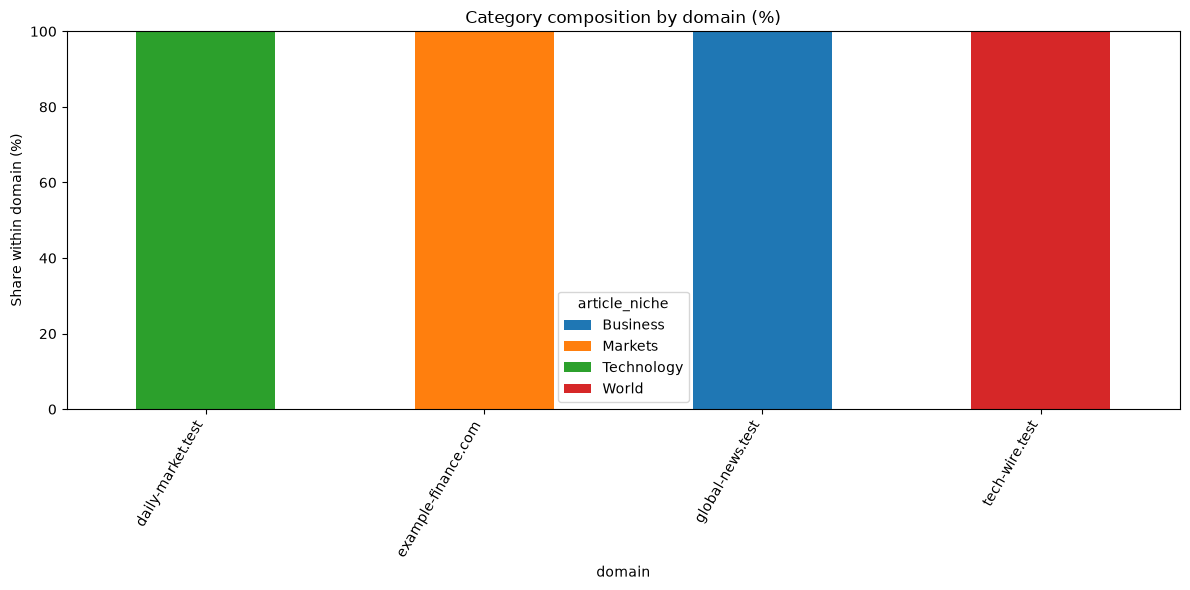

In [18]:
if COLS["domain"] and COLS["category"]:
    mix = pd.crosstab(df[COLS["domain"]], df[COLS["category"]], normalize="index") * 100
    display(mix.round(1).head(25))
    ax = mix.head(15).plot(kind="bar", stacked=True, figsize=(12, 6))
    ax.set_title("Category composition by domain (%)")
    ax.set_ylabel("Share within domain (%)")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()

## 12. Investigate suspicious extraction patterns

The heuristics below flag candidates for manual review. Thresholds are starting points, not universal rules. Do not automatically delete short/long articles.

In [19]:
suspicious = pd.Series(False, index=df.index)
if "_content_words" in df.columns:
    suspicious |= df["_content_words"].fillna(0).lt(40)
    if df["_content_words"].notna().any():
        suspicious |= df["_content_words"].gt(df["_content_words"].quantile(.99))
if COLS["title"]:
    pattern = r"access denied|captcha|robot check|page not found|403 forbidden|enable javascript"
    suspicious |= df[COLS["title"]].astype("string").str.contains(pattern, case=False, na=False)
if "_publish_to_scrape_minutes" in df.columns:
    suspicious |= df["_publish_to_scrape_minutes"].lt(0).fillna(False)

review_cols = [c for c in [COLS["domain"], COLS["title"], COLS["published"], COLS["scraped"], "_title_words", "_content_words", "_publish_to_scrape_minutes", COLS["url"]] if c]
suspicious_records = df.loc[suspicious, review_cols].copy()
print(f"Suspicious candidates: {len(suspicious_records)} / {len(df)} ({len(suspicious_records)/max(len(df), 1):.1%})")
display(suspicious_records.head(50))

Suspicious candidates: 63 / 240 (26.2%)


,domain,title_clean,published_at_utc,scraped_at_utc,_title_words,_content_words,_publish_to_scrape_minutes,news_url_clean
0,example-finance.com,Retail sales data signals a shift in consumer demand,2026-08-06 08:31:00+00:00,2026-08-06 10:40:00+00:00,9,29,129.0,https://example-finance.com/article/0
4,example-finance.com,Oil prices move after latest economic data release,2026-08-26 23:32:00+00:00,2026-08-27 02:18:00+00:00,8,19,166.0,https://example-finance.com/article/4
7,tech-wire.test,Stocks fall as traders react to central bank comments,2026-09-11 20:12:00+00:00,2026-09-11 21:54:00+00:00,9,30,102.0,https://tech-wire.test/article/7
16,example-finance.com,Stocks fall as traders react to central bank comments,2026-08-31 19:02:00+00:00,2026-08-31 21:34:00+00:00,9,12,152.0,https://example-finance.com/article/16
21,daily-market.test,Stocks fall as traders react to central bank comments,2026-08-23 05:56:00+00:00,2026-08-23 08:13:00+00:00,9,19,137.0,https://daily-market.test/article/21
24,example-finance.com,Technology shares rise as investors assess new forecasts,2026-09-16 21:27:00+00:00,2026-09-16 22:55:00+00:00,8,22,88.0,https://example-finance.com/article/24
28,example-finance.com,Major technology firm introduces a new product,2026-09-02 17:25:00+00:00,2026-09-02 18:23:00+00:00,7,30,58.0,https://example-finance.com/article/28
40,example-finance.com,Oil prices move after latest economic data release,2026-08-10 21:55:00+00:00,2026-08-11 00:54:00+00:00,8,37,179.0,https://example-finance.com/article/40
42,global-news.test,Retail sales data signals a shift in consumer demand,2026-09-12 00:45:00+00:00,2026-09-12 02:56:00+00:00,9,27,131.0,https://global-news.test/article/42
49,daily-market.test,Analysts discuss outlook for global financial markets,2026-09-16 16:52:00+00:00,2026-09-16 19:24:00+00:00,7,21,152.0,https://daily-market.test/article/49


## 13. Optional numeric correlation matrix
Use only numeric features; avoid IDs and encoded identifiers.

,_title_chars,_title_words,_content_chars,_content_words,_published_hour_utc,_publish_to_scrape_minutes
_title_chars,1.00,0.11,-0.08,-0.08,-0.04,0.02
_title_words,0.11,1.00,-0.04,-0.04,-0.14,0.06
_content_chars,-0.08,-0.04,1.00,1.00,-0.04,-0.17
_content_words,-0.08,-0.04,1.00,1.00,-0.05,-0.17
_published_hour_utc,-0.04,-0.14,-0.04,-0.05,1.00,0.06
_publish_to_scrape_minutes,0.02,0.06,-0.17,-0.17,0.06,1.00


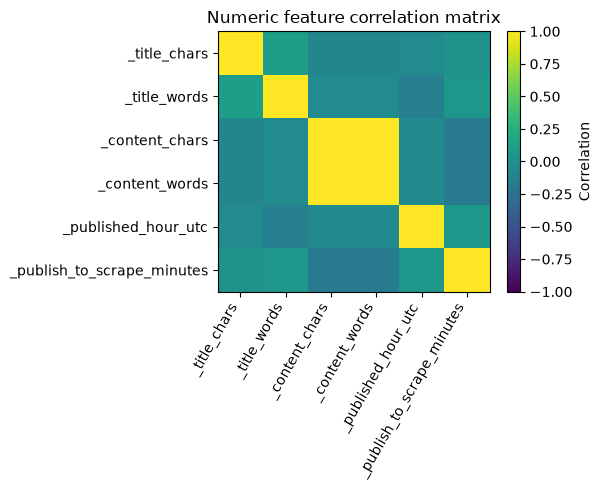

In [20]:
numeric = df.select_dtypes(include=np.number)
if numeric.shape[1] >= 2:
    corr = numeric.corr(numeric_only=True)
    display(corr.round(2))
    fig, ax = plt.subplots(figsize=(max(6, len(corr.columns)*.8), max(5, len(corr.columns)*.7)))
    image = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)
    ax.set_title("Numeric feature correlation matrix")
    fig.colorbar(image, ax=ax, label="Correlation")
    plt.tight_layout()
    plt.show()
else:
    print("Fewer than two numeric columns are available.")

## 14. Export EDA outputs
Summaries and candidate records are exported for review. The original source dataset is not overwritten.

In [21]:
overview.to_csv(OUTPUT_DIR / "column_profile.csv")
missing_summary.to_csv(OUTPUT_DIR / "missingness_summary.csv")
pd.Series(duplicate_stats, name="row_count").to_csv(OUTPUT_DIR / "duplicate_summary.csv")
if "source_counts" in globals():
    source_counts.rename("articles").to_csv(OUTPUT_DIR / "source_distribution.csv")
if "category_counts" in globals():
    category_counts.rename("articles").to_csv(OUTPUT_DIR / "category_distribution.csv")
suspicious_records.to_csv(OUTPUT_DIR / "suspicious_candidates.csv", index=False)
summary = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "missing_pct_by_column": {str(k): float(v) for k, v in overview["missing_pct"].items()},
    "detected_fields": COLS,
    "outputs_directory": str(OUTPUT_DIR.resolve()),
}
with open(OUTPUT_DIR / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print("Saved outputs to:", OUTPUT_DIR.resolve())
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved outputs to: /Users/ummehabiba/Downloads/eda_output
['category_distribution.csv', 'column_profile.csv', 'duplicate_summary.csv', 'eda_summary.json', 'missingness_summary.csv', 'source_distribution.csv', 'suspicious_candidates.csv']


## 15. How to write EDA findings

For each finding, record:
1. **Observation:** What does the chart/table show?
2. **Evidence:** A count, percentage, median, range, or comparison.
3. **Interpretation:** What might explain the pattern?
4. **Caveat:** What else could explain it?
5. **Action:** Investigate, validate, collect more data, or design a feature.

**Illustrative example only:** “One source contributes 38% of rows. This may overrepresent that publisher, although it could reflect genuine publishing volume or the scraper schedule. Compare source coverage over time before deciding whether source balancing is needed.” Do not copy illustrative numbers as your own results.

## 16. Student exercises

1. Find the top three domains and calculate their combined share of articles.
2. Compare median content length across the five largest domains.
3. Compare missing author and publication-time percentages by domain.
4. Plot daily article counts and identify gaps or spikes; suggest two explanations.
5. Investigate repeated titles across different domains: syndication or scraper duplication?
6. Select one suspicious record and document why it deserves review.
7. Write five findings using observation → evidence → interpretation → caveat → action.
8. Explain why automatically deleting every short article or repeated title is unsafe.

## Key takeaways and next lecture

- EDA reveals structure, distributions, missingness, duplicates, source concentration, temporal patterns, and relationships.
- Source and time analyses can expose collection bias and scraper reliability issues.
- Suspicious rows are review candidates, not automatically invalid records.
- Keep EDA separate from data cleaning and log evidence-based findings.

**Recommended next lecture:** Feature Engineering for News/Text Data — converting validated articles into meaningful numerical and categorical signals before embeddings and machine learning.